[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eirasf/GCED-AA2/blob/main/es/lab7/lab7.ipynb)
# Práctica 7: Residual neural networks


### Pre-requisitos. Instalar paquetes

Para la primera parte de este Laboratorio 8 necesitaremos torch. Además, como habitualmente, fijaremos la semilla aleatoria para asegurar la reproducibilidad de los experimentos.

In [11]:
import torch

#Fijamos la semilla para poder reproducir los resultados
import os
import numpy as np
import random
seed=1234
os.environ['PYTHONHASHSEED']=str(seed)
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

### Carga del conjunto de datos

De nuevo, seguimos empleando el conjunto *Titanic* ya empleado en los laboratorios anteriores.


In [12]:
# TODO - Carga el conjunto Titanic. No es necesario hacer particiones, pero asegúrate de que las
# variables estén en la escala apropiada

import pandas as pd
from sklearn.preprocessing import StandardScaler
import torch

# Descargamos el dataset Titanic directamente desde un repositorio público
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Seleccionamos variables numéricas sencillas para la demostración y eliminamos nulos
features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
target = 'Survived'

data_cleaned = df[features + [target]].dropna()

X = data_cleaned[features].values
y = data_cleaned[target].values

# Escalamos los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convertimos a tensores de PyTorch
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

print(f"X_tensor shape: {X_tensor.shape}")
print(f"y_tensor shape: {y_tensor.shape}")

X_tensor shape: torch.Size([714, 5])
y_tensor shape: torch.Size([714, 1])


## Visualización del desvanecimiento del gradiente
Las Residual neural networks se ocupan de que los gradientes no se desvanezcan cuando la red es muy profunda. Vamos a visualizar este problema creando una red profunda y mostrando las dimensiones de los gradientes que llegan a cada capa.

### Creamos un modelo *Sequential*
Creamos un modelo *Sequential* para ajustar a los datos de entrada siguiendo las especificaciones dadas.

In [13]:
# TODO - Define en model una red MLP con 20 capas ocultas, con activación sigmoide, con 10 unidades por capa.
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_dim, output_dim, num_hidden_layers = 20, hidden_units = 10, activation=nn.Sigmoid()):
        super(MLP, self).__init__()

        # TODO - Completa la clase
        layers = []
        # Capa de entrada
        layers.append(nn.Linear(input_dim, hidden_units))
        layers.append(activation)

        # Capas ocultas intermedias
        for _ in range(num_hidden_layers - 1):
            layers.append(nn.Linear(hidden_units, hidden_units))
            layers.append(activation)

        # Capa de salida
        layers.append(nn.Linear(hidden_units, output_dim))

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

### Entrenamiento del modelo
Entrena el modelo durante 10 epochs. En el bucle de entrenamiento, guarda en un diccionario con el formato mostrado el histórico de gradientes de cada capa.

In [14]:
# TODO - Entrena el modelo durante 10 epochs
# Cambia tu train step guardar los gradientes en un diccionario con este formato:
# g_hist = {name: [] for name, param in model.named_parameters() if 'weight' in name}
# Por cada parámetro que se llame weight (ignoraremos los bias en este ejercicio),
# guardaremos una lista con un valor por cada epoch. En la lista de cada parámetro,
# debes guardar la media de las normas de los gradientes de ese parámetro durante
# los pasos de cada epoch.
# Para calcular la norma del gradiente de un parámetro puedes usar:
# torch.norm(param.grad.detach()))

# Instanciamos el modelo MLP
model = MLP(input_dim=5, output_dim=1)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

# Inicializamos el diccionario de historial de gradientes
g_hist = {name: [] for name, param in model.named_parameters() if 'weight' in name}

# Entrenamiento durante 10 epochs
epochs = 10
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    outputs = model(X_tensor)
    loss = criterion(outputs, y_tensor)

    loss.backward()

    # Guardamos los gradientes de este paso
    for name, param in model.named_parameters():
        if 'weight' in name:
            if param.grad is not None:
                grad_norm = torch.norm(param.grad.detach()).item()
                g_hist[name].append(grad_norm)
            else:
                g_hist[name].append(0.0)

    optimizer.step()
    print(f"{epoch}/{epochs}:\tLoss:{loss.item():.4f}")

0/10:	Loss:0.8124
1/10:	Loss:0.7875
2/10:	Loss:0.7670
3/10:	Loss:0.7501
4/10:	Loss:0.7362
5/10:	Loss:0.7249
6/10:	Loss:0.7157
7/10:	Loss:0.7082
8/10:	Loss:0.7021
9/10:	Loss:0.6971


Ahora que hemos hecho algunos pasos de entrenamiento, representamos el tamaño medio de los pesos de cada capa.

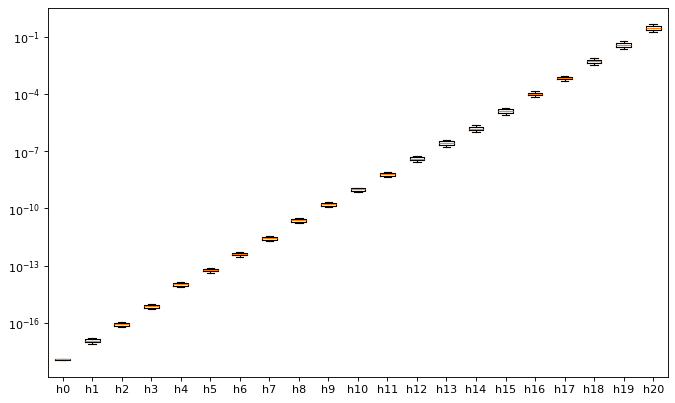

In [15]:
from matplotlib import pyplot as plt
# Ahora accedemos al historial de gradientes y representamos el tamaño medio de los gradientes de cada capa.
plt.figure(figsize=(10, 6), dpi=80)
plt.boxplot(g_hist.values())
plt.yscale('log')
plt.xticks(ticks=range(1,len(g_hist)+1), labels=[f'h{int(k.split('.')[1])//2}' for k in g_hist.keys()])
plt.show()

## Comparativa
 - ¿Qué observas en los pesos?
 - ¿Ocurre lo mismo utilizando ReLU como función de activación de las capas ocultas?
 - Repite la prueba con las distintas [funciones de activación](https://docs.pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity) que tengan sentido.
 - Prueba a utilizar He initialization para tus capas Dense (ver código en la celda siguiente)
 - (OPCIONAL) Alarga el entrenamiento y prueba distintos optimizadores para intentar que el modelo entrene correctamente.

In [16]:
# Ejemplo de He initialization
# for layer in self.model:
#     if isinstance(layer, nn.Linear):
#         nn.init.kaiming_uniform_(layer.weight, nonlinearity='relu')
#         nn.init.zeros_(layer.bias)

In [17]:
# Abajo se muestra el resultado con ReLU y He initialization

---
# Parte 2

### Creación del bloque con conexión residual

En una red neuronal *feed-forward* convencional, la salida de cada capa se utiliza como entrada de las capa siguiente.

<img src="https://github.com/eirasf/GCED-AA2/blob/main/es/lab7/img/resnet.png?raw=1" alt="Dos capas en una red FF" width="400"/>

En contraste, en una ResNet se introducen bloques que incluyen conexiones residuales con el objetivo de favorecer la propagación de los gradientes.

<img src="https://github.com/eirasf/GCED-AA2/blob/main/es/lab7/img/resnet-2.png?raw=1" alt="Dos capas en una red FF con conexión residual" width="400"/>

A pesar de que las ResNet se suelen utilizar con redes convolucionales, en este Laboratorio utilizaremos una red *feed-forward*.

Para poder utilizar este tipo de bloques en nuestra arquitectura definiremos un nuevo tipo de modelo denominado `BlockWithSkipConnection` que consistirá en lo representado en la imagen:
 - Una primera capa con activación, cuya salida sirve de entrada a...
 - Una segunda capa lineal (sin activación), cuya salida sirve de entrada a...
 - A una operación suma que la añade a la entrada original a la primera capa. La salida de esta suma servirá de entrada a...
 - Una función de activación, cuya salida será la salida del bloque.

Utilizaremos la función sigmoide como función de activación en ambos casos. La entrada y la salida del bloque deberán tener la misma dimensión para que se pueda realizar la suma. Por simplicidad, mantendremos la salida de la primera capa con la misma dimensión.

In [18]:
class BlockWithSkipConnection(nn.Module):
    def __init__(self, dim, outer_activation = nn.Sigmoid(), inner_activation = nn.Sigmoid()):
        super(BlockWithSkipConnection, self).__init__()
        # TODO - Completa la clase
        self.linear1 = nn.Linear(dim, dim)
        self.inner_act = inner_activation
        self.linear2 = nn.Linear(dim, dim)
        self.outer_act = outer_activation

    def forward(self, x):
        out = self.linear1(x)
        out = self.inner_act(out)
        out = self.linear2(out)
        # Sumamos la entrada original (skip connection) y aplicamos la activación exterior
        out = out + x
        out = self.outer_act(out)
        return out

## Creamos un modelo utilizando los nuevos bloques
Creamos un modelo *MLPWithSkipConnections* para ajustar a los datos de entrada siguiendo las especificaciones dadas. Deberá incluir una capa de entrada de 10 unidades con activación sigmoide, 10 de los nuevos bloques y la capa de salida apropiada.

In [19]:
class MLPWithSkipConnections(nn.Module):
    def __init__(self, input_dim, output_dim, num_blocks = 10, hidden_units = 10, activation = nn.Sigmoid()):
        super(MLPWithSkipConnections, self).__init__()
        # TODO - Completa la clase

        # Capa inicial para proyectar a la dimensión oculta (10 unidades)
        self.input_layer = nn.Sequential(
            nn.Linear(input_dim, hidden_units),
            activation
        )

        # Bloques residuales
        blocks = []
        for _ in range(num_blocks):
            blocks.append(BlockWithSkipConnection(hidden_units, outer_activation=activation, inner_activation=activation))
        self.blocks = nn.Sequential(*blocks)

        # Capa final de salida
        self.output_layer = nn.Linear(hidden_units, output_dim)

    def forward(self, x):
        out = self.input_layer(x)
        out = self.blocks(out)
        out = self.output_layer(out)
        return out

0/10:	Loss:0.6814
1/10:	Loss:0.6802
2/10:	Loss:0.6792
3/10:	Loss:0.6784
4/10:	Loss:0.6778
5/10:	Loss:0.6773
6/10:	Loss:0.6769
7/10:	Loss:0.6766
8/10:	Loss:0.6764
9/10:	Loss:0.6762


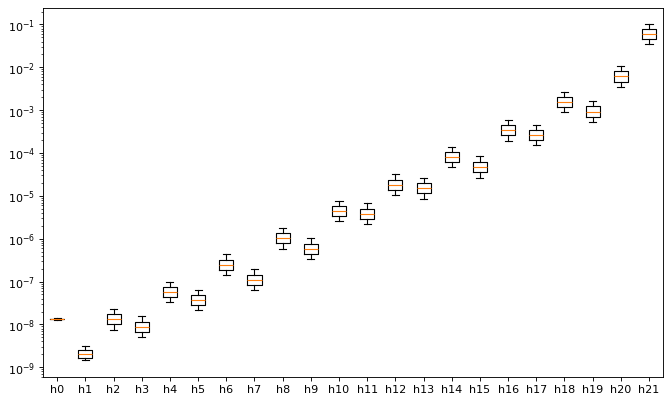

In [20]:
# TODO - Entrena el modelo guardando en g_hist el histórico de gradientes

# Instanciamos el modelo con conexiones residuales
model_res = MLPWithSkipConnections(input_dim=5, output_dim=1)
criterion_res = nn.BCEWithLogitsLoss()
optimizer_res = torch.optim.SGD(model_res.parameters(), lr=0.1)

# Inicializamos el historial de gradientes
g_hist = {name: [] for name, param in model_res.named_parameters() if 'weight' in name}

epochs = 10
for epoch in range(epochs):
    model_res.train()
    optimizer_res.zero_grad()

    outputs = model_res(X_tensor)
    loss = criterion_res(outputs, y_tensor)

    loss.backward()

    # Guardamos los gradientes
    for name, param in model_res.named_parameters():
        if 'weight' in name:
            if param.grad is not None:
                grad_norm = torch.norm(param.grad.detach()).item()
                g_hist[name].append(grad_norm)
            else:
                g_hist[name].append(0.0)

    optimizer_res.step()
    print(f"{epoch}/{epochs}:\tLoss:{loss.item():.4f}")

# Ahora accedemos al historial de gradientes y representamos el tamaño medio de los gradientes de cada capa.
plt.figure(figsize=(10, 6), dpi=80)
plt.boxplot(g_hist.values())
plt.yscale('log')
# Para evitar el error de conversión de texto a int, generamos etiquetas basadas en el índice del parámetro
plt.xticks(ticks=range(1, len(g_hist) + 1), labels=[f'h{i}' for i in range(len(g_hist))])
plt.show()

## Comparativa
 - Contrasta los resultados con los obtenidos en la primera parte
 - Cambia las activaciones del exteriores del bloque y de la primera capa oculta de la red a ReLU y observa la diferencia.
 - Alarga el entrenamiento y prueba distintos optimizadores para intentar que el modelo entrene correctamente.

### 1. Comparativa de resultados (Sigmoid)
En el primer modelo (MLP secuencial profundo), el gradiente se desvanece de forma crítica hacia las primeras capas del modelo ($h0$ a $h4$), llegando a magnitudes del orden de $10^{-18}$. Esto imposibilita que la red aprenda de forma efectiva en las primeras capas.

En cambio, en el modelo con conexiones residuales (ResNet), el gradiente en las primeras capas se mantiene en niveles del orden de $10^{-8}$ a $10^{-9}$. Aunque es pequeño, es miles de millones de veces mayor que en la red convencional, lo que ilustra cómo el *skip connection* ayuda a que fluya el gradiente sin desvanecerse tan rápido.

### 2. Cambio de activaciones a ReLU en el Modelo Residual
Definiremos, entrenaremos y evaluaremos un nuevo modelo residual utilizando la función de activación ReLU como la activación exterior de los bloques y la capa de entrada oculta.

Epoch 0/10 - Loss: 0.7406
Epoch 1/10 - Loss: 0.7251
Epoch 2/10 - Loss: 0.7142
Epoch 3/10 - Loss: 0.7056
Epoch 4/10 - Loss: 0.6985
Epoch 5/10 - Loss: 0.6925
Epoch 6/10 - Loss: 0.6872
Epoch 7/10 - Loss: 0.6825
Epoch 8/10 - Loss: 0.6782
Epoch 9/10 - Loss: 0.6744


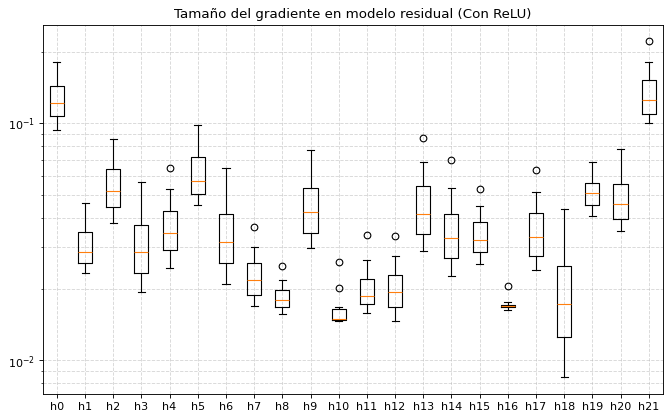

In [21]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Instanciamos el modelo residual con ReLU en lugar de Sigmoid
model_res_relu = MLPWithSkipConnections(input_dim=5, output_dim=1, activation=nn.ReLU())
criterion_res_relu = nn.BCEWithLogitsLoss()
optimizer_res_relu = torch.optim.SGD(model_res_relu.parameters(), lr=0.1)

g_hist_relu = {name: [] for name, param in model_res_relu.named_parameters() if 'weight' in name}

epochs = 10
for epoch in range(epochs):
    model_res_relu.train()
    optimizer_res_relu.zero_grad()

    outputs = model_res_relu(X_tensor)
    loss = criterion_res_relu(outputs, y_tensor)

    loss.backward()

    # Guardamos los gradientes
    for name, param in model_res_relu.named_parameters():
        if 'weight' in name:
            if param.grad is not None:
                grad_norm = torch.norm(param.grad.detach()).item()
                g_hist_relu[name].append(grad_norm)
            else:
                g_hist_relu[name].append(0.0)

    optimizer_res_relu.step()
    print(f"Epoch {epoch}/{epochs} - Loss: {loss.item():.4f}")

# Visualización de gradientes con ReLU
plt.figure(figsize=(10, 6), dpi=80)
plt.boxplot(g_hist_relu.values())
plt.yscale('log')
plt.xticks(ticks=range(1, len(g_hist_relu) + 1), labels=[f'h{i}' for i in range(len(g_hist_relu))])
plt.title("Tamaño del gradiente en modelo residual (Con ReLU)")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

### 3. Entrenamiento extendido con el optimizador Adam
Vamos a extender el entrenamiento a 100 epochs utilizando el optimizador `Adam` para observar la correcta convergencia del modelo residual con ReLU.

Epoch 10/100 - Loss: 0.6361
Epoch 20/100 - Loss: 0.5818
Epoch 30/100 - Loss: 0.5625
Epoch 40/100 - Loss: 0.5520
Epoch 50/100 - Loss: 0.5472
Epoch 60/100 - Loss: 0.5415
Epoch 70/100 - Loss: 0.5364
Epoch 80/100 - Loss: 0.5313
Epoch 90/100 - Loss: 0.5332
Epoch 100/100 - Loss: 0.5228


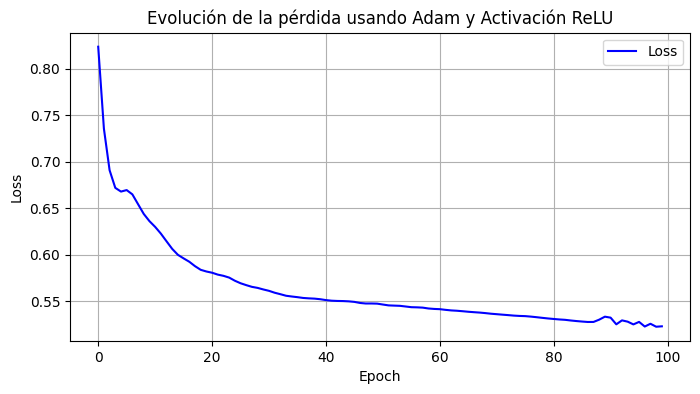

In [22]:
model_adam = MLPWithSkipConnections(input_dim=5, output_dim=1, activation=nn.ReLU())
criterion_adam = nn.BCEWithLogitsLoss()
# Usamos Adam que adapta dinámicamente el learning rate
optimizer_adam = torch.optim.Adam(model_adam.parameters(), lr=0.01)

losses = []
epochs = 100

for epoch in range(epochs):
    model_adam.train()
    optimizer_adam.zero_grad()

    outputs = model_adam(X_tensor)
    loss = criterion_adam(outputs, y_tensor)

    loss.backward()
    optimizer_adam.step()

    losses.append(loss.item())
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} - Loss: {loss.item():.4f}")

# Representación de la evolución de la pérdida
plt.figure(figsize=(8, 4))
plt.plot(losses, label='Loss', color='blue')
plt.title('Evolución de la pérdida usando Adam y Activación ReLU')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()